# 인공신경망(ANN) 회귀 실습 - 보안 사고 대응 비용 예측

**목표:** 보안 사고 한 건의 여러 정보(공격 유형, 산업군, 감염된 호스트 수, 탐지까지 걸린 시간 등)를 입력받아 그 사고의 **대응 비용(단위: 천 달러, $K)** 을 예측하는 **회귀(Regression)** 모델을 만듭니다.

<div class="alert alert-warning"><strong>주의:</strong> 이 데이터셋은 <strong>합성(가상) 데이터</strong>입니다.  스크립트로 현실적인 패턴(랜섬웨어가 피싱보다 비싸다, 의료·금융 업종은 비용이 높다, 탐지가 늦을수록 비용이 커진다 등)을 흉내 내어 만들었습니다. 실제 사고 데이터가 아니므로 현실 세계에 대한 결론을 내리는 데 사용하면 안 됩니다.</div>

## 표(Tabular) 데이터 다루기
엑셀이나 SQL 테이블처럼 행과 열로 된 데이터를 신경망에 넣으려면, **범주형(categorical)** 값과 **연속형(continuous)** 값을 따로 처리해야 합니다. 이 노트북에서 다루는 핵심 개념은 다음과 같습니다.
* **연속형 vs 범주형 값** - 숫자 크기에 의미가 있는 값(예: 감염 호스트 수)과, 종류를 나타내는 값(예: 공격 유형)
* **임베딩(Embedding)** - 범주형 값을 학습 가능한 숫자 벡터로 바꾸는 방법
* **배치 정규화(Batch Normalization)** - 입력 값들의 크기(스케일)를 비슷하게 맞추는 층
* **드롭아웃(Dropout)** - 학습 중 일부 뉴런을 무작위로 꺼서 과적합을 막는 층

## 1단계: 필요한 라이브러리 불러오기
* <tt>torch</tt>, <tt>torch.nn</tt>: 신경망을 만들고 학습시키는 PyTorch 라이브러리
* <tt>numpy</tt>: 배열 계산
* <tt>pandas</tt>: CSV 파일을 읽고 표 형태로 데이터를 다루기
* <tt>matplotlib</tt>: 그래프 그리기

In [3]:
import os
# 04a와 마찬가지로 CPU에서 학습합니다.
# GPU를 숨겨 두면, NVIDIA 드라이버가 오래되어 생기는 CUDA 오류도 피할 수 있습니다.
# 이 설정은 반드시 torch를 import 하기 "전에" 실행해야 효과가 있습니다.
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '-1')

import torch                # PyTorch 기본 라이브러리 (텐서, 자동 미분 등)
import torch.nn as nn       # 신경망 층(Linear, Embedding, BatchNorm 등)과 손실 함수

import numpy as np          # 수치 계산용 배열 라이브러리
import pandas as pd         # 표(DataFrame) 형태의 데이터 처리 라이브러리
import matplotlib.pyplot as plt   # 그래프 그리기 라이브러리
%matplotlib inline
# ↑ 그래프를 노트북 안에 바로 표시하도록 하는 Jupyter 명령어

## 2단계: 보안 사고 데이터셋 불러오기
6만 건의 레코드가 있고, 한 행이 보안 사고 한 건입니다. 4주(2024년 3월 4일 ~ 3월 31일) 동안 탐지된 사고들이며, 각 열의 의미는 다음과 같습니다.

| 열 이름 | 의미 |
|---|---|
| <tt>detected_datetime</tt> | 사고가 탐지된 날짜와 시각 (UTC 기준) |
| <tt>response_cost_k</tt> | **예측할 정답(label)**: 대응 비용, 단위는 천 달러($K) |
| <tt>cost_class</tt> | 비용이 $100K 이상이면 1, 아니면 0 (이번 회귀 실습에서는 사용하지 않음) |
| <tt>attack_type</tt> | 공격 유형 (피싱, 악성코드, 랜섬웨어, DDoS, SQL 인젝션 등) |
| <tt>industry</tt> | 피해 조직의 산업군 (금융, 의료, 교육 등) |
| <tt>src_latitude / src_longitude</tt> | 공격 출발지의 대략적인 위도/경도 (GeoIP) |
| <tt>dst_latitude / dst_longitude</tt> | 피해 사이트의 위도/경도 |
| <tt>hosts_affected</tt> | 피해를 입은 호스트(컴퓨터) 수 |
| <tt>data_exfil_gb</tt> | 외부로 유출된 데이터 양 (GB) |
| <tt>time_to_detect_hrs</tt> | 사고 발생부터 탐지까지 걸린 시간 (시간 단위) |
| <tt>cvss_score</tt> | 악용된 취약점의 심각도 점수 (0~10) |
| <tt>employees</tt> | 피해 조직의 직원 수 |

레코드는 이미 무작위로 섞여 있습니다.

In [4]:
# CSV 파일을 읽어 DataFrame(표)으로 만듭니다.
# '../Data/' 는 현재 노트북 폴더의 상위 폴더에 있는 Data 폴더를 뜻합니다.
df = pd.read_csv('./Data/SecurityIncidents.csv')

# 처음 5개 행을 출력해서 데이터가 어떻게 생겼는지 확인합니다.
df.head()

,detected_datetime,response_cost_k,cost_class,attack_type,industry,src_latitude,src_longitude,dst_latitude,dst_longitude,hosts_affected,data_exfil_gb,time_to_detect_hrs,cvss_score,employees
0,2024-03-06 11:58:35 UTC,74.70,0,Malware,Technology,40.044233,117.991181,0.914661,104.244946,26,0.76,7.8,4.7,2445
1,2024-03-25 16:05:54 UTC,35.48,0,Phishing,Retail,40.031545,127.817074,43.511939,-79.114732,2,0.12,32.2,6.7,2005
2,2024-03-22 07:52:19 UTC,160.65,1,DDoS,Manufacturing,37.603389,50.816497,43.136998,-79.661414,30,0.01,21.5,8.1,62
3,2024-03-16 06:55:34 UTC,218.89,1,Malware,Healthcare,2.467286,102.373496,-33.941897,151.236021,24,1.66,65.1,6.2,306
4,2024-03-16 02:59:10 UTC,426.87,1,Ransomware,Government,39.682988,116.338039,-33.574722,151.128360,34,0.05,6.7,8.5,1234


In [6]:
# 정답(label) 열인 대응 비용의 통계 요약을 봅니다.
# count(개수), mean(평균), std(표준편차), min/max(최소/최대), 25%/50%/75%(사분위수)
df['response_cost_k'].describe()

count    60000.000000
mean       121.961379
std         97.363430
min         10.370000
25%         50.410000
50%         93.555000
75%        162.160000
max        600.000000
Name: response_cost_k, dtype: float64

대응 비용은 약 \$10K ~ \$600K 범위이고, 평균은 약 \$122K, 중앙값(50%)은 약 \$94K 입니다.

## 3단계: 공격 거리 계산하기 (새로운 특성 만들기)
택시 데이터의 승차/하차 지점처럼, 여기에도 GPS 좌표가 두 쌍 있습니다: **공격이 출발한 곳**과 **피해가 발생한 곳**입니다.
두 지점 사이의 거리를 <a href='https://en.wikipedia.org/wiki/Haversine_formula'>하버사인(haversine) 공식</a>으로 계산해 새로운 열(<tt>dist_km</tt>)로 추가합니다. 국경을 넘는 공격은 법률 대응·국제 공조 등 추가 작업이 필요해 비용이 커지는 경향이 있습니다.

하버사인 공식은 구(지구) 표면 위 두 점 사이의 거리를 구합니다.

${\displaystyle d=2r\arcsin \left({\sqrt {\sin ^{2}\left({\frac {\varphi _{2}-\varphi _{1}}{2}}\right)+\cos(\varphi _{1})\:\cos(\varphi _{2})\:\sin ^{2}\left({\frac {\lambda _{2}-\lambda _{1}}{2}}\right)}}\right)}$

* $r$: 지구 반지름 (평균 6371 km)
* $\varphi_1, \varphi_2$: 두 지점의 위도
* $\lambda_1, \lambda_2$: 두 지점의 경도

In [7]:
def haversine_distance(df, lat1, long1, lat2, long2):
    """
    DataFrame(df) 안의 두 GPS 좌표 쌍 사이의 하버사인 거리(km)를 계산합니다.
    lat1, long1: 첫 번째 지점의 위도/경도 열 이름
    lat2, long2: 두 번째 지점의 위도/경도 열 이름
    """
    r = 6371  # 지구의 평균 반지름 (km)

    # 삼각함수는 라디안 단위를 사용하므로, 도(degree)를 라디안(radian)으로 변환합니다.
    phi1 = np.radians(df[lat1])     # 지점 1의 위도
    phi2 = np.radians(df[lat2])     # 지점 2의 위도

    delta_phi = np.radians(df[lat2]-df[lat1])        # 위도 차이
    delta_lambda = np.radians(df[long2]-df[long1])   # 경도 차이

    # 하버사인 공식 계산
    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))     # 두 지점 사이의 중심각
    d = (r * c)  # 중심각 × 반지름 = 거리 (km)

    return d

In [8]:
# 공격 출발지(src) → 피해지(dst) 거리를 계산해 'dist_km' 열로 추가합니다.
# 함수가 열 전체(6만 행)를 한 번에 계산합니다 (반복문 없이 벡터 연산).
df['dist_km'] = haversine_distance(df,'src_latitude', 'src_longitude', 'dst_latitude', 'dst_longitude')
df.head()

,detected_datetime,response_cost_k,cost_class,attack_type,industry,src_latitude,src_longitude,dst_latitude,dst_longitude,hosts_affected,data_exfil_gb,time_to_detect_hrs,cvss_score,employees,dist_km
0,2024-03-06 11:58:35 UTC,74.70,0,Malware,Technology,40.044233,117.991181,0.914661,104.244946,26,0.76,7.8,4.7,2445,4567.851627
1,2024-03-25 16:05:54 UTC,35.48,0,Phishing,Retail,40.031545,127.817074,43.511939,-79.114732,2,0.12,32.2,6.7,2005,10340.417045
2,2024-03-22 07:52:19 UTC,160.65,1,DDoS,Manufacturing,37.603389,50.816497,43.136998,-79.661414,30,0.01,21.5,8.1,62,9740.368317
3,2024-03-16 06:55:34 UTC,218.89,1,Malware,Healthcare,2.467286,102.373496,-33.941897,151.236021,24,1.66,65.1,6.2,306,6514.395356
4,2024-03-16 02:59:10 UTC,426.87,1,Ransomware,Government,39.682988,116.338039,-33.574722,151.128360,34,0.05,6.7,8.5,1234,8896.869793


## 4단계: 날짜/시간에서 유용한 정보 뽑아내기
밤이나 주말에 탐지된 사고는 대응 인력이 부족해서 비용이 더 드는 경우가 많습니다. 그래서 **시(Hour)**, **오전/오후(AMorPM)**, **요일(Weekday)** 을 새 열로 만듭니다.

중요한 것은 피해 사이트의 **현지 시각**인데, 데이터는 UTC로 저장되어 있습니다.
* 04a에서는 모든 택시가 뉴욕에 있었으므로 단순히 4시간을 뺐습니다.
* 여기서는 피해 사이트가 전 세계에 흩어져 있으므로, **경도로 시간대를 근사**합니다. 지구는 1시간에 15도씩 자전하므로, 시차는 대략 <tt>경도 / 15</tt> 시간입니다. (예: 뉴욕 경도 -74 → -74/15 ≈ -5시간)

In [9]:
# 1) 피해 사이트 경도로 시차(시간)를 근사합니다. round()로 정수 시간으로 반올림합니다.
tz_offset = pd.to_timedelta((df['dst_longitude'] / 15).round(), unit='h')

# 2) 문자열 '2024-03-06 11:58:35 UTC'에서 앞 19글자(' UTC' 제외)만 잘라 datetime으로 변환한 뒤,
#    시차를 더해 현지 시각을 구합니다.
df['LocalDate'] = pd.to_datetime(df['detected_datetime'].str[:19]) + tz_offset

# 3) 현지 시각에서 '시(0~23)'를 뽑습니다.
df['Hour'] = df['LocalDate'].dt.hour

# 4) 12시 이전이면 'am', 이후면 'pm'
df['AMorPM'] = np.where(df['Hour']<12,'am','pm')

# 5) 요일을 'Mon', 'Tue' ... 같은 약어 문자열로 만듭니다.
df['Weekday'] = df['LocalDate'].dt.strftime("%a")
df.head()

,detected_datetime,response_cost_k,cost_class,attack_type,industry,src_latitude,src_longitude,dst_latitude,dst_longitude,hosts_affected,data_exfil_gb,time_to_detect_hrs,cvss_score,employees,dist_km,LocalDate,Hour,AMorPM,Weekday
0,2024-03-06 11:58:35 UTC,74.70,0,Malware,Technology,40.044233,117.991181,0.914661,104.244946,26,0.76,7.8,4.7,2445,4567.851627,2024-03-06 18:58:35,18,pm,Wed
1,2024-03-25 16:05:54 UTC,35.48,0,Phishing,Retail,40.031545,127.817074,43.511939,-79.114732,2,0.12,32.2,6.7,2005,10340.417045,2024-03-25 11:05:54,11,am,Mon
2,2024-03-22 07:52:19 UTC,160.65,1,DDoS,Manufacturing,37.603389,50.816497,43.136998,-79.661414,30,0.01,21.5,8.1,62,9740.368317,2024-03-22 02:52:19,2,am,Fri
3,2024-03-16 06:55:34 UTC,218.89,1,Malware,Healthcare,2.467286,102.373496,-33.941897,151.236021,24,1.66,65.1,6.2,306,6514.395356,2024-03-16 16:55:34,16,pm,Sat
4,2024-03-16 02:59:10 UTC,426.87,1,Ransomware,Government,39.682988,116.338039,-33.574722,151.128360,34,0.05,6.7,8.5,1234,8896.869793,2024-03-16 12:59:10,12,pm,Sat


In [10]:
# 현지 시각 기준 가장 이른 시각
df['LocalDate'].min()

Timestamp('2024-03-03 16:02:02')

In [11]:
# 현지 시각 기준 가장 늦은 시각
df['LocalDate'].max()

Timestamp('2024-04-01 09:51:57')

## 5단계: 범주형 열과 연속형 열 나누기
* **범주형(categorical)**: 값이 "종류"를 나타냅니다. 크기 비교가 의미 없습니다. (예: 'Phishing'과 'Ransomware' 중 어느 것이 "더 큰" 값은 아님)
* **연속형(continuous)**: 값의 크기 자체에 의미가 있습니다. (예: 감염 호스트 60대는 2대보다 많음)

<tt>Hour</tt>는 숫자이지만 범주형으로 다룹니다. 23시와 0시는 숫자로는 멀지만 실제로는 1시간 차이이기 때문에, 각 시간을 별도의 "종류"로 보고 모델이 직접 관계를 학습하게 합니다.

In [12]:
# 현재 DataFrame에 있는 모든 열 이름 확인
df.columns

Index(['detected_datetime', 'response_cost_k', 'cost_class', 'attack_type',
       'industry', 'src_latitude', 'src_longitude', 'dst_latitude',
       'dst_longitude', 'hosts_affected', 'data_exfil_gb',
       'time_to_detect_hrs', 'cvss_score', 'employees', 'dist_km', 'LocalDate',
       'Hour', 'AMorPM', 'Weekday'],
      dtype='str')

In [13]:
# 범주형 열 5개: 시, 오전/오후, 요일, 공격 유형, 산업군
cat_cols = ['Hour', 'AMorPM', 'Weekday', 'attack_type', 'industry']

# 연속형 열 10개: 좌표 4개, 감염 호스트 수, 유출 데이터 양, 탐지 시간, CVSS 점수, 직원 수, 공격 거리
cont_cols = ['src_latitude', 'src_longitude', 'dst_latitude', 'dst_longitude', 'hosts_affected',
             'data_exfil_gb', 'time_to_detect_hrs', 'cvss_score', 'employees', 'dist_km']

# 정답(label) 열: 예측하려는 대응 비용
y_col = ['response_cost_k']

## 6단계: 범주형 값을 숫자 코드로 바꾸기 (Categorify)
신경망은 'Phishing' 같은 문자열을 직접 처리할 수 없습니다. pandas의 **category 자료형**을 사용하면 각 범주에 0, 1, 2, ... 같은 정수 코드가 붙습니다.
* <tt>.cat.categories</tt>: 범주 이름 목록 (알파벳 순으로 정렬됨)
* <tt>.cat.codes</tt>: 각 행의 정수 코드

In [14]:
# 범주형 열 5개를 모두 category 자료형으로 변환합니다.
for cat in cat_cols:
    df[cat] = df[cat].astype('category')

In [15]:
# 각 열의 자료형 확인: 범주형 5개 열이 'category'로 바뀐 것을 볼 수 있습니다.
df.dtypes

detected_datetime                str
response_cost_k              float64
cost_class                     int64
attack_type                 category
industry                    category
src_latitude                 float64
src_longitude                float64
dst_latitude                 float64
dst_longitude                float64
hosts_affected                 int64
data_exfil_gb                float64
time_to_detect_hrs           float64
cvss_score                   float64
employees                      int64
dist_km                      float64
LocalDate             datetime64[us]
Hour                        category
AMorPM                      category
Weekday                     category
dtype: object

In [16]:
# 공격 유형의 범주 이름 목록. 이 순서대로 0, 1, 2, ... 코드가 붙습니다.
df['attack_type'].cat.categories

Index(['Brute Force', 'DDoS', 'Data Exfiltration', 'Insider Threat', 'Malware',
       'Phishing', 'Ransomware', 'SQL Injection'],
      dtype='str')

In [17]:
# 처음 5개 행의 공격 유형이 어떤 정수 코드로 바뀌었는지 확인
df['attack_type'].head().cat.codes

0    4
1    5
2    1
3    4
4    6
dtype: int8

In [18]:
# 산업군의 범주 이름 목록
df['industry'].cat.categories

Index(['Education', 'Finance', 'Government', 'Healthcare', 'Manufacturing',
       'Retail', 'Technology'],
      dtype='str')

In [19]:
# 요일의 범주 이름 목록 (요일 순서가 아니라 알파벳 순서임에 주의!)
df['Weekday'].cat.categories

Index(['Fri', 'Mon', 'Sat', 'Sun', 'Thu', 'Tue', 'Wed'], dtype='str')

이제 범주형 열 5개의 코드를 <tt>numpy.stack</tt>으로 합쳐 하나의 2차원 배열(행 = 사고, 열 = 범주형 특성)로 만듭니다.

In [20]:
# 각 열의 코드 배열을 열 방향(axis=1)으로 쌓아 (60000, 5) 모양의 배열을 만듭니다.
cats = np.stack([df[col].cat.codes.values for col in cat_cols], 1)
cats[:5]   # 처음 5행 확인

array([[18,  1,  6,  4,  6],
       [11,  0,  1,  5,  5],
       [ 2,  0,  0,  1,  4],
       [16,  1,  2,  4,  3],
       [12,  1,  2,  6,  2]], dtype=int8)

## 7단계: numpy 배열을 PyTorch 텐서로 변환하기
PyTorch 모델은 **텐서(tensor)** 를 입력으로 받습니다.
* 범주형 코드 → <tt>int64</tt> 텐서 (Embedding 층은 정수 인덱스를 입력으로 받음)
* 연속형 값과 정답 → <tt>float32</tt> 텐서 (BatchNorm이 제대로 동작하려면 float64가 아닌 float32여야 함)

In [21]:
# 범주형 코드를 int64(정수) 텐서로 변환
cats = torch.tensor(cats, dtype=torch.int64)
cats[:5]

tensor([[18,  1,  6,  4,  6],
        [11,  0,  1,  5,  5],
        [ 2,  0,  0,  1,  4],
        [16,  1,  2,  4,  3],
        [12,  1,  2,  6,  2]])

연속형 값은 여기서 직접 정규화하지 않습니다. 모델의 첫 번째 <tt>BatchNorm1d</tt> 층이 정규화를 해 줍니다.
이 데이터에서는 특히 중요합니다: <tt>employees</tt>는 10 ~ 100,000 범위인데 <tt>cvss_score</tt>는 0 ~ 10 범위라 크기 차이가 매우 큽니다. 정규화하지 않으면 큰 값을 가진 열이 학습을 지배하게 됩니다.

In [22]:
# 연속형 열 10개를 (60000, 10) 배열로 쌓은 뒤 float32 텐서로 변환
conts = np.stack([df[col].values for col in cont_cols], 1)
conts = torch.tensor(conts, dtype=torch.float)
conts[:5]

tensor([[ 4.0044e+01,  1.1799e+02,  9.1466e-01,  1.0424e+02,  2.6000e+01,
          7.6000e-01,  7.8000e+00,  4.7000e+00,  2.4450e+03,  4.5679e+03],
        [ 4.0032e+01,  1.2782e+02,  4.3512e+01, -7.9115e+01,  2.0000e+00,
          1.2000e-01,  3.2200e+01,  6.7000e+00,  2.0050e+03,  1.0340e+04],
        [ 3.7603e+01,  5.0816e+01,  4.3137e+01, -7.9661e+01,  3.0000e+01,
          1.0000e-02,  2.1500e+01,  8.1000e+00,  6.2000e+01,  9.7404e+03],
        [ 2.4673e+00,  1.0237e+02, -3.3942e+01,  1.5124e+02,  2.4000e+01,
          1.6600e+00,  6.5100e+01,  6.2000e+00,  3.0600e+02,  6.5144e+03],
        [ 3.9683e+01,  1.1634e+02, -3.3575e+01,  1.5113e+02,  3.4000e+01,
          5.0000e-02,  6.7000e+00,  8.5000e+00,  1.2340e+03,  8.8969e+03]])

In [23]:
# 정답(대응 비용)을 float32 텐서로 변환하고, (60000, 1) 모양의 열 벡터로 만듭니다.
# reshape(-1,1): 행 개수는 자동(-1), 열은 1개
y = torch.tensor(df[y_col].values, dtype=torch.float).reshape(-1,1)
y[:5]

tensor([[ 74.7000],
        [ 35.4800],
        [160.6500],
        [218.8900],
        [426.8700]])

In [24]:
# 세 텐서의 모양(shape) 확인: 행 개수(60000)가 모두 같아야 합니다.
cats.shape, conts.shape, y.shape

(torch.Size([60000, 5]), torch.Size([60000, 10]), torch.Size([60000, 1]))

## 8단계: 임베딩 크기 정하기
**임베딩(Embedding)** 은 각 범주(예: 'Ransomware')를 학습 가능한 숫자 벡터로 바꿉니다. 학습이 진행되면서 비슷한 성격의 범주는 비슷한 벡터를 갖게 됩니다.

임베딩 벡터 길이를 정하는 경험 법칙: **(범주 개수 + 1) // 2, 단 최대 50**

In [25]:
# 각 범주형 열의 범주 개수: 시(24), 오전/오후(2), 요일(7), 공격 유형(8), 산업군(7)
cat_szs = [len(df[col].cat.categories) for col in cat_cols]

# (범주 개수, 임베딩 벡터 길이) 쌍의 목록을 만듭니다.
emb_szs = [(size, min(50, (size+1)//2)) for size in cat_szs]
emb_szs

[(24, 12), (2, 1), (7, 4), (8, 4), (7, 4)]

## 9단계: TabularModel(표 데이터용 신경망) 정의하기
04a와 동일한 모델입니다. 데이터가 흐르는 순서는 다음과 같습니다.

1. **범주형 입력** → 열마다 <tt>Embedding</tt> → 벡터들을 이어 붙임 → <tt>Dropout</tt>
2. **연속형 입력** → <tt>BatchNorm1d</tt>로 정규화
3. 1과 2를 이어 붙여 하나의 벡터로 만듦 (임베딩 길이 합 25 + 연속형 10 = 35개 값)
4. 은닉층 반복: <tt>Linear → ReLU → BatchNorm1d → Dropout</tt>
5. 마지막 <tt>Linear</tt> 층이 값 1개(예측 비용)를 출력

In [26]:
class TabularModel(nn.Module):   # 모든 PyTorch 모델은 nn.Module을 상속합니다.

    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        """
        emb_szs: (범주 개수, 임베딩 길이) 튜플 목록
        n_cont : 연속형 변수 개수
        out_sz : 출력 크기 (회귀는 1)
        layers : 은닉층 뉴런 수 목록 (예: [200, 100])
        p      : 드롭아웃 확률
        """
        super().__init__()   # 부모 클래스(nn.Module) 초기화

        # 범주형 열마다 Embedding 층을 하나씩 만들어 ModuleList에 담습니다.
        # (ModuleList에 넣어야 PyTorch가 이 층들의 가중치를 학습 대상으로 인식합니다.)
        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni,nf in emb_szs])

        # 임베딩 출력에 적용할 드롭아웃
        self.emb_drop = nn.Dropout(p)

        # 연속형 입력을 정규화할 배치 정규화 층
        self.bn_cont = nn.BatchNorm1d(n_cont)

        layerlist = []
        n_emb = sum((nf for ni,nf in emb_szs))   # 임베딩 벡터 길이의 합
        n_in = n_emb + n_cont                    # 첫 번째 은닉층의 입력 크기

        # 은닉층 쌓기: Linear → ReLU → BatchNorm → Dropout
        for i in layers:
            layerlist.append(nn.Linear(n_in,i))        # 완전 연결층
            layerlist.append(nn.ReLU(inplace=True))    # 활성화 함수 (음수는 0으로)
            layerlist.append(nn.BatchNorm1d(i))        # 층 출력 정규화
            layerlist.append(nn.Dropout(p))            # 과적합 방지
            n_in = i                                   # 다음 층의 입력 크기 = 이번 층의 출력 크기

        # 출력층: 마지막 은닉층 → 출력 값 (회귀이므로 활성화 함수 없음)
        layerlist.append(nn.Linear(layers[-1],out_sz))

        # 층 목록을 순서대로 실행하는 하나의 모듈로 묶습니다.
        self.layers = nn.Sequential(*layerlist)

    def forward(self, x_cat, x_cont):
        """순전파: 입력 데이터가 모델을 통과해 예측값이 되는 과정"""
        embeddings = []
        # i번째 범주형 열(x_cat[:,i])을 i번째 Embedding 층에 통과시킵니다.
        for i,e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:,i]))
        x = torch.cat(embeddings, 1)   # 임베딩 벡터들을 옆으로 이어 붙임
        x = self.emb_drop(x)

        x_cont = self.bn_cont(x_cont)      # 연속형 입력 정규화
        x = torch.cat([x, x_cont], 1)      # 범주형 + 연속형 결합
        x = self.layers(x)                 # 은닉층과 출력층 통과
        return x

In [27]:
# 결과를 재현할 수 있도록 난수 시드를 고정합니다 (가중치 초기값이 매번 같아짐).
torch.manual_seed(33)

# 모델 생성: 임베딩 설정, 연속형 변수 10개, 출력 1개, 은닉층 [200, 100], 드롭아웃 0.4
model = TabularModel(emb_szs, conts.shape[1], 1, [200,100], p=0.4)
model   # 모델 구조 출력

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
    (3): Embedding(8, 4)
    (4): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=35, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=1, bias=True)
  )
)

## 10단계: 손실 함수와 옵티마이저 정의하기
* **손실 함수**: <tt>MSELoss</tt>(평균 제곱 오차)를 쓰고, 학습할 때 제곱근을 씌워 **RMSE**(평균 제곱근 오차)로 만듭니다. RMSE는 정답과 같은 단위(천 달러)라서 해석하기 쉽습니다.
* **옵티마이저**: <tt>Adam</tt>. 손실을 줄이는 방향으로 가중치를 업데이트합니다.



In [28]:
criterion = nn.MSELoss()  # 평균 제곱 오차. 학습 시 torch.sqrt()를 씌워 RMSE로 사용합니다.

# model.parameters(): 모델의 모든 학습 가능한 가중치와 편향
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## 11단계: 학습용/테스트용 데이터 나누기
6만 건 전체를 사용하고, 그중 **20%(1만 2천 건)** 는 학습에 사용하지 않고 테스트용으로 남겨 둡니다. 모델이 처음 보는 데이터에서도 잘 예측하는지 확인하기 위해서입니다.
레코드가 이미 무작위로 섞여 있으므로 앞부분을 학습용, 뒷부분을 테스트용으로 잘라 써도 됩니다.

In [29]:
batch_size = 60000                  # 사용할 전체 데이터 수
test_size = int(batch_size * .2)    # 테스트용 데이터 수 (20% = 12000)

# 앞의 48000개 → 학습용, 뒤의 12000개 → 테스트용
cat_train = cats[:batch_size-test_size]
cat_test = cats[batch_size-test_size:batch_size]
con_train = conts[:batch_size-test_size]
con_test = conts[batch_size-test_size:batch_size]
y_train = y[:batch_size-test_size]
y_test = y[batch_size-test_size:batch_size]

In [30]:
# 학습용, 테스트용 데이터 개수 확인
len(cat_train), len(cat_test)

(48000, 12000)

## 12단계: 모델 학습시키기
한 **에포크(epoch)** 마다 다음 과정을 반복합니다.
1. **순전파**: 학습 데이터 전체를 모델에 넣어 예측값을 구함
2. **손실 계산**: 예측값과 정답의 RMSE 계산
3. **기울기 초기화**: 이전 에포크의 기울기를 지움 (PyTorch는 기울기를 누적하기 때문)
4. **역전파**: 손실을 줄이려면 각 가중치를 어느 방향으로 바꿔야 하는지(기울기) 계산
5. **가중치 업데이트**: 옵티마이저가 기울기를 이용해 가중치를 조정

CPU에서 약 3~5분 정도 걸립니다.

In [31]:
import time
start_time = time.time()   # 학습 시작 시각 기록

epochs = 300     # 전체 학습 데이터를 300번 반복해서 학습
losses = []      # 에포크별 손실 값을 저장할 리스트 (나중에 그래프용)

for i in range(epochs):
    i+=1   # 출력할 때 에포크 번호가 1부터 시작하도록

    # 1) 순전파: 학습 데이터로 예측
    y_pred = model(cat_train, con_train)

    # 2) 손실 계산: MSE에 제곱근을 씌워 RMSE로
    loss = torch.sqrt(criterion(y_pred, y_train))

    # 손실 값을 숫자로 저장합니다.
    # .item()으로 숫자만 꺼내야 기울기 정보가 붙은 텐서가 쌓이지 않습니다.
    losses.append(loss.item())

    # 화면이 너무 길어지지 않도록 25 에포크마다 한 번만 출력
    if i%25 == 1:
        print(f'epoch: {i:3}  loss: {loss.item():10.8f}')

    optimizer.zero_grad()   # 3) 기울기 초기화
    loss.backward()         # 4) 역전파: 기울기 계산
    optimizer.step()        # 5) 가중치 업데이트

print(f'epoch: {i:3}  loss: {loss.item():10.8f}')   # 마지막 에포크 결과
print(f'\nDuration: {time.time() - start_time:.0f} seconds')   # 총 학습 시간

epoch:   1  loss: 156.59654236
epoch:  26  loss: 134.91856384
epoch:  51  loss: 97.65257263
epoch:  76  loss: 56.46753311
epoch: 101  loss: 37.24530792
epoch: 126  loss: 34.92663574
epoch: 151  loss: 34.07907867
epoch: 176  loss: 33.34377289
epoch: 201  loss: 33.05061340
epoch: 226  loss: 32.64611053
epoch: 251  loss: 33.01510239
epoch: 276  loss: 32.64625931
epoch: 300  loss: 32.87552643

Duration: 111 seconds


## 13단계: 손실 그래프 그리기
에포크가 진행될수록 손실(RMSE)이 줄어드는지 확인합니다. 그래프가 평평해지면 더 학습해도 크게 나아지지 않는다는 뜻입니다.

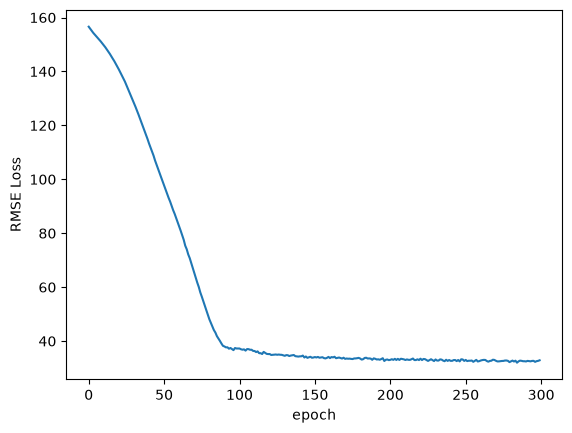

In [32]:
plt.plot(range(epochs), losses)   # x축: 에포크, y축: 손실
plt.ylabel('RMSE Loss')
plt.xlabel('epoch');   # 줄 끝의 ; 는 불필요한 텍스트 출력을 숨깁니다.

## 14단계: 모델 검증하기 (테스트 데이터로 평가)
학습에 사용하지 않은 테스트 데이터 전체를 모델에 넣고 정답과 비교합니다.
* <tt>model.eval()</tt>: **평가 모드**로 전환합니다. 드롭아웃이 꺼지고, BatchNorm이 학습 중에 계산해 둔 통계를 사용합니다. 그래서 실행할 때마다 예측값이 달라지지 않습니다. (04a에는 이 단계가 없지만 넣는 것이 올바른 방법입니다.)
* <tt>torch.no_grad()</tt>: 평가할 때는 가중치를 바꾸지 않으므로 기울기 계산을 끕니다. 메모리와 시간이 절약됩니다.

In [33]:
model.eval()            # 평가 모드로 전환
with torch.no_grad():   # 기울기 계산 끄기
    y_val = model(cat_test, con_test)            # 테스트 데이터 예측
    loss = torch.sqrt(criterion(y_val, y_test))  # 테스트 RMSE
print(f'RMSE: {loss:.8f}')

RMSE: 40.48005676


RMSE는 정답과 같은 단위이므로, 이 값은 **예측이 평균적으로 몇 천 달러 정도 틀리는지**를 나타냅니다.
비교 기준으로 테스트 정답의 표준편차를 봅시다. 이 값은 "모든 사고에 대해 평균 비용 하나만 예측했을 때"의 오차와 같습니다. 모델의 RMSE가 이보다 훨씬 작다면 모델이 의미 있는 패턴을 학습한 것입니다.

In [34]:
# 항상 평균값만 예측했을 때의 오차(= 표준편차)
print(f'Std of test labels: {y_test.std().item():.8f}')

Std of test labels: 96.02973175


이제 처음 50개 테스트 데이터의 예측값, 실제값, 차이를 나란히 보겠습니다.

In [35]:
# 열 제목 출력 (>12, >8 은 오른쪽 정렬 너비)
print(f'{"PREDICTED":>12} {"ACTUAL":>8} {"DIFF":>8}')
for i in range(50):
    diff = np.abs(y_val[i].item()-y_test[i].item())   # 예측값과 실제값 차이의 절댓값
    print(f'{i+1:2}. {y_val[i].item():8.4f} {y_test[i].item():8.4f} {diff:8.4f}')

   PREDICTED   ACTUAL     DIFF
 1.  74.9202  89.4100  14.4898
 2.  70.7157  70.9700   0.2543
 3.  45.0648  39.9000   5.1648
 4.  42.6265  46.1400   3.5135
 5. 314.8836 432.6100 117.7264
 6. 109.9234 180.9700  71.0466
 7. 250.9271 200.7900  50.1371
 8.  91.8741 110.6500  18.7759
 9. 177.8910 182.8500   4.9590
10. 192.1279 221.0300  28.9021
11.  63.6654  71.6900   8.0246
12.  45.1689  32.6300  12.5389
13.  45.7217  51.3200   5.5983
14.  40.1900  29.1600  11.0300
15.  99.5396 132.6000  33.0604
16.  61.5584 116.3400  54.7816
17.  42.1446  30.1300  12.0146
18. 319.2202 312.8200   6.4002
19.  43.1121  36.4700   6.6421
20. 239.8096 280.8700  41.0604
21.  43.7351  45.7700   2.0349
22.  34.2988  30.6000   3.6988
23.  45.0404  51.0600   6.0196
24.  61.8080  52.2800   9.5280
25.  38.1391  28.8500   9.2891
26. 327.0027 331.1000   4.0974
27. 137.0477 182.2800  45.2323
28.  92.4453 101.1300   8.6847
29. 114.1710 228.4000 114.2290
30.  62.3167 123.5900  61.2733
31.  46.2420  36.8700   9.3720
32.  36.

학습률, 에포크 수, 은닉층 크기, 드롭아웃 확률 등을 바꿔 보면서 더 좋은 모델을 만들어 보세요.

## 15단계: 모델 저장하기
학습된 **가중치와 편향(<tt>state_dict</tt>)** 만 파일로 저장하는 것이 권장 방법입니다. 모델 구조(클래스)는 코드로 다시 정의하면 됩니다.
학습하지 않은 모델로 기존 파일을 덮어쓰지 않도록, 학습이 끝났는지 확인한 뒤에 저장합니다.

In [36]:
# 손실 기록 개수가 에포크 수와 같으면 = 학습이 끝까지 진행되었으면 저장
if len(losses) == epochs:
    torch.save(model.state_dict(), 'SecurityCostRegrModel.pt')
else:
    print('Model has not been trained. Consider loading a trained model instead.')

## 16단계: 저장된 모델 불러오기 (처음부터 다시 시작하는 상황)
실제 상황을 흉내 내기 위해, 여기서 **커널을 재시작(Restart)** 한 뒤 진행해 보세요. 커널을 재시작하면 지금까지 만든 변수가 모두 사라지므로, import와 함수·클래스 정의를 다시 실행해야 합니다.

또한 <tt>attack_type</tt>, <tt>industry</tt>, <tt>Weekday</tt>의 범주 이름 목록을 pandas가 사용한 것과 **같은 순서(알파벳 순)** 로 준비해야 합니다. 그래야 새 데이터도 학습 때와 같은 정수 코드를 받습니다. 순서가 다르면 모델이 'Phishing'을 'Ransomware'로 착각하는 식의 오류가 생깁니다.

In [37]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '-1')   # torch import 전에 GPU 숨기기

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

# 거리 계산 함수 (3단계와 동일)
def haversine_distance(df, lat1, long1, lat2, long2):
    r = 6371
    phi1 = np.radians(df[lat1])
    phi2 = np.radians(df[lat2])
    delta_phi = np.radians(df[lat2]-df[lat1])
    delta_lambda = np.radians(df[long2]-df[long1])
    a = np.sin(delta_phi/2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda/2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))
    return r * c

# 모델 클래스 (9단계와 동일). 저장된 가중치를 담을 "그릇"이 필요합니다.
class TabularModel(nn.Module):
    def __init__(self, emb_szs, n_cont, out_sz, layers, p=0.5):
        super().__init__()
        self.embeds = nn.ModuleList([nn.Embedding(ni, nf) for ni,nf in emb_szs])
        self.emb_drop = nn.Dropout(p)
        self.bn_cont = nn.BatchNorm1d(n_cont)
        layerlist = []
        n_emb = sum((nf for ni,nf in emb_szs))
        n_in = n_emb + n_cont
        for i in layers:
            layerlist.append(nn.Linear(n_in,i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
        layerlist.append(nn.Linear(layers[-1],out_sz))
        self.layers = nn.Sequential(*layerlist)
    def forward(self, x_cat, x_cont):
        embeddings = []
        for i,e in enumerate(self.embeds):
            embeddings.append(e(x_cat[:,i]))
        x = torch.cat(embeddings, 1)
        x = self.emb_drop(x)
        x_cont = self.bn_cont(x_cont)
        x = torch.cat([x, x_cont], 1)
        return self.layers(x)

# pandas가 코드를 붙인 순서(알파벳 순)와 똑같은 범주 이름 목록
# 리스트에서의 위치(index)가 곧 정수 코드입니다. 예: 'Ransomware' → 6
weekdays = ['Fri', 'Mon', 'Sat', 'Sun', 'Thu', 'Tue', 'Wed']
attack_types = ['Brute Force', 'DDoS', 'Data Exfiltration', 'Insider Threat',
                'Malware', 'Phishing', 'Ransomware', 'SQL Injection']
industries = ['Education', 'Finance', 'Government', 'Healthcare',
              'Manufacturing', 'Retail', 'Technology']

이제 학습할 때와 **똑같은 설정**으로 모델을 만들고, 저장해 둔 가중치를 불러옵니다. 설정이 하나라도 다르면 가중치 모양이 맞지 않아 오류가 납니다.

In [38]:
# 8단계에서 계산한 임베딩 크기를 그대로 적어 줍니다.
emb_szs = [(24, 12), (2, 1), (7, 4), (8, 4), (7, 4)]

# 연속형 변수 10개, 출력 1개, 은닉층 [200,100], 드롭아웃 0.4 (학습 때와 동일)
model2 = TabularModel(emb_szs, 10, 1, [200,100], p=0.4)

In [39]:
# 저장된 가중치를 불러와 모델에 넣습니다.
model2.load_state_dict(torch.load('SecurityCostRegrModel.pt'));

# 예측에 사용하기 전에 반드시 평가 모드로 전환합니다!
# (샘플 1개만 넣을 때 학습 모드라면 BatchNorm이 제대로 동작하지 않습니다.)
model2.eval()

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(24, 12)
    (1): Embedding(2, 1)
    (2): Embedding(7, 4)
    (3): Embedding(8, 4)
    (4): Embedding(7, 4)
  )
  (emb_drop): Dropout(p=0.4, inplace=False)
  (bn_cont): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=35, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=1, bias=True)
  )
)

## 17단계: 새로운 사고 데이터로 예측하는 함수 만들기
새 사고 정보를 받아 **지금까지의 전처리 단계(거리 계산, 현지 시각 변환, 범주 코드 변환, 텐서 변환)를 똑같이 적용**한 뒤 모델에 넣는 함수입니다.
* 사고 정보를 **딕셔너리**로 넘길 수 있습니다.
* 딕셔너리 없이 <tt>test_data(model2)</tt>로 호출하면 값을 하나씩 입력하라는 질문이 나옵니다.

In [40]:
def test_data(mdl, incident=None):   # mdl: 학습된 모델, incident: 사고 정보 딕셔너리
    # ---- 1. 새 데이터 입력 받기 ----
    # 딕셔너리가 주어지지 않으면 input()으로 값을 하나씩 물어봅니다.
    if incident is None:
        incident = {
            'attack_type': input(f'Attack type {attack_types}? '),
            'industry': input(f'Industry {industries}? '),
            'src_latitude': float(input('Attack source latitude?  ')),
            'src_longitude': float(input('Attack source longitude? ')),
            'dst_latitude': float(input('Victim site latitude?  ')),
            'dst_longitude': float(input('Victim site longitude? ')),
            'hosts_affected': int(input('How many hosts affected? ')),
            'data_exfil_gb': float(input('Data exfiltrated (GB)? ')),
            'time_to_detect_hrs': float(input('Hours until detection? ')),
            'cvss_score': float(input('CVSS score (0-10)? ')),
            'employees': int(input('Number of employees? ')),
            'detected_datetime': input('Detection date and time (UTC)?\nFormat as YYYY-MM-DD HH:MM:SS     '),
        }

    # ---- 2. 전처리: 학습 데이터에 했던 것과 똑같이 ----
    dfx = pd.DataFrame(incident, index=[0])   # 행 1개짜리 DataFrame

    # 공격 거리 계산 (3단계)
    dfx['dist_km'] = haversine_distance(dfx,'src_latitude', 'src_longitude',
                                        'dst_latitude', 'dst_longitude')

    # UTC → 현지 시각 변환 (4단계)
    tz_offset = pd.to_timedelta((dfx['dst_longitude'] / 15).round(), unit='h')
    dfx['LocalDate'] = pd.to_datetime(dfx['detected_datetime']) + tz_offset

    # 범주형 값을 정수 코드로 직접 변환 (6단계)
    # 행이 1개뿐이라 .astype('category')를 쓰면 코드가 달라지므로, 위에서 만든 목록의 위치로 변환합니다.
    dfx['Hour'] = dfx['LocalDate'].dt.hour                  # 시(0~23)는 값 자체가 코드
    dfx['AMorPM'] = np.where(dfx['Hour']<12,0,1)            # am=0, pm=1
    dfx['Weekday'] = weekdays.index(dfx['LocalDate'].dt.strftime("%a")[0])
    dfx['attack_type'] = attack_types.index(dfx['attack_type'][0])
    dfx['industry'] = industries.index(dfx['industry'][0])

    # ---- 3. 범주형/연속형 텐서 만들기 (7단계) ----
    # 열 순서가 학습 때와 반드시 같아야 합니다!
    cat_cols = ['Hour', 'AMorPM', 'Weekday', 'attack_type', 'industry']
    cont_cols = ['src_latitude', 'src_longitude', 'dst_latitude', 'dst_longitude', 'hosts_affected',
                 'data_exfil_gb', 'time_to_detect_hrs', 'cvss_score', 'employees', 'dist_km']
    xcats = np.stack([dfx[col].values for col in cat_cols], 1)
    xcats = torch.tensor(xcats, dtype=torch.int64)
    xconts = np.stack([dfx[col].values for col in cont_cols], 1)
    xconts = torch.tensor(xconts, dtype=torch.float)

    # ---- 4. 예측 (역전파 없이) ----
    with torch.no_grad():
        z = mdl(xcats, xconts)
    print(f'The predicted response cost is ${z.item():.2f}K')
    return z.item()

## 18단계: 새로운 사고 데이터로 예측해 보기
아래는 학습 데이터에 있던 값의 범위입니다. 이 범위를 크게 벗어나는 값을 넣으면 예측을 믿기 어렵습니다. (모델은 본 적 없는 영역을 잘 모릅니다.)
<table style="display: inline-block">
<tr><th>열</th><th>최솟값</th><th>최댓값</th></tr>
<tr><td>src_latitude / src_longitude</td><td>-30 / -128</td><td>61 / 131</td></tr>
<tr><td>dst_latitude / dst_longitude</td><td>-35 / -124</td><td>53 / 152</td></tr>
<tr><td>hosts_affected</td><td>1</td><td>210</td></tr>
<tr><td>data_exfil_gb</td><td>0</td><td>92</td></tr>
<tr><td>time_to_detect_hrs</td><td>0.1</td><td>248</td></tr>
<tr><td>cvss_score</td><td>0.1</td><td>10</td></tr>
<tr><td>employees</td><td>10</td><td>100,000</td></tr>
<tr><td>detected_datetime</td><td>2024-03-04 00:00:00</td><td>2024-03-31 23:59:59</td></tr>
</table>

**병원을 노린 랜섬웨어 공격**과 **작은 IT 회사의 피싱 사고**를 비교해 봅시다. 두 사고 모두 동유럽에서 출발한 공격이고, 뉴욕 현지 시각으로 토요일 밤에 탐지되었습니다.

In [41]:
# 사례 1: 병원(Healthcare) 랜섬웨어 공격
ransomware = {'attack_type': 'Ransomware', 'industry': 'Healthcare',
              'src_latitude': 50.45, 'src_longitude': 30.52,   # 공격 출발지 (동유럽)
              'dst_latitude': 40.71, 'dst_longitude': -74.01,  # 피해지: 뉴욕
              'hosts_affected': 60,         # 감염 호스트 60대
              'data_exfil_gb': 5.0,         # 데이터 5GB 유출
              'time_to_detect_hrs': 48.0,   # 탐지까지 이틀
              'cvss_score': 9.1,            # 매우 심각한 취약점
              'employees': 5000,            # 직원 5천 명
              'detected_datetime': '2024-03-17 02:30:00'}   # UTC 기준 = 뉴욕 토요일 21:30

z = test_data(model2, ransomware)

The predicted response cost is $558.41K


In [42]:
# 사례 2: 같은 시각, 같은 장소에서 일어난 소규모 IT 회사의 피싱 사고
# dict(기존딕셔너리, 키=새값)은 기존 값을 복사하면서 지정한 값만 바꿉니다.
phishing = dict(ransomware, attack_type='Phishing', industry='Technology',
                hosts_affected=2,          # 감염 호스트 2대
                data_exfil_gb=0.0,         # 유출 없음
                time_to_detect_hrs=3.0,    # 3시간 만에 탐지
                cvss_score=4.0,            # 중간 정도 심각도
                employees=200)             # 직원 200명

z = test_data(model2, phishing)

The predicted response cost is $27.34K


랜섬웨어 사고의 예상 비용이 피싱 사고보다 훨씬 큰 것을 볼 수 있습니다. 모델이 공격 유형, 산업군, 피해 규모, 탐지 시간 등이 비용에 미치는 영향을 학습했다는 뜻입니다.

직접 다른 사고를 만들어 예측해 보세요! <tt>test_data(model2)</tt>를 실행하면 값을 하나씩 입력할 수 있습니다.

## 수고하셨습니다!